# Introduction

### Imports

In [109]:
#Basic Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Machine Learning Imports
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, recall_score, precision_score, f1_score, \
    ConfusionMatrixDisplay, confusion_matrix, balanced_accuracy_score
from sklearn.model_selection import GridSearchCV
import xgboost as xgb
from xgboost import XGBClassifier
from xgboost import plot_importance
import warnings;

#cross validation imports
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)
from sklearn.model_selection import StratifiedKFold, cross_val_score, KFold

In [110]:
df = pd.read_csv("term-deposit-marketing-2020.csv")

### Initial Examination of the Data
Familiarizing with the data set, checking the size and shape, checking for null and duplicate values.

In [111]:
df.head(25)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,no


In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        40000 non-null  int64
 1   job        40000 non-null  str  
 2   marital    40000 non-null  str  
 3   education  40000 non-null  str  
 4   default    40000 non-null  str  
 5   balance    40000 non-null  int64
 6   housing    40000 non-null  str  
 7   loan       40000 non-null  str  
 8   contact    40000 non-null  str  
 9   day        40000 non-null  int64
 10  month      40000 non-null  str  
 11  duration   40000 non-null  int64
 12  campaign   40000 non-null  int64
 13  y          40000 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.3 MB


Looking at this dataset I see several categorical variables that will need to be transformed into numeric. something will need to be done with day and month to make a date column, but I need to check if you can feed a date into a machine learning model. the dataset is complete with no null values, so we will not need to address that. We will need to check for potential duplicates and get descriptives on all the variables to get a sense of what we're working with.

In [113]:
df.describe()

,age,balance,day,duration,campaign
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,40.544600,1274.277550,16.017225,254.824300,2.882175
std,9.641776,2903.769716,8.278127,259.366498,3.239051
min,19.000000,-8019.000000,1.000000,0.000000,1.000000
25%,33.000000,54.000000,8.000000,100.000000,1.000000
50%,39.000000,407.000000,17.000000,175.000000,2.000000
75%,48.000000,1319.000000,21.000000,313.000000,3.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000


I want to take a closer look at balance, that -8019 looks a little odd to me, but the balance might include debt, in which case that wouldn't be too odd. The max is also pretty high on balance so that could be another potential outlier. Date and age look as expected. Duration of the last contact has a high maximum, meaning at least one customer had a pretty long conversation with the person who contacted them. Finally in Campaign, which is number of contacts with the customer, I'm seeing a max of 63 which, given the 75th percentile is 3, seems to be an error or an extreme outlier.

In [114]:
df.duplicated().sum()

np.int64(0)

There are no duplicates in this data. This data set is already well cleaned so we can jump straight into the exploratory data analysis and examining outliers.

# Exploratory Data Analysis

## Examining Numerical Data
Creating histograms to examine the distribution and look for outliers. Examining Outliers to check for potential data entry errors.

(array([1.6120e+03, 1.1462e+04, 1.0133e+04, 8.3760e+03, 5.5840e+03,
        2.6890e+03, 8.3000e+01, 4.2000e+01, 1.6000e+01, 3.0000e+00]),
 array([19. , 26.6, 34.2, 41.8, 49.4, 57. , 64.6, 72.2, 79.8, 87.4, 95. ]),
 <BarContainer object of 10 artists>)

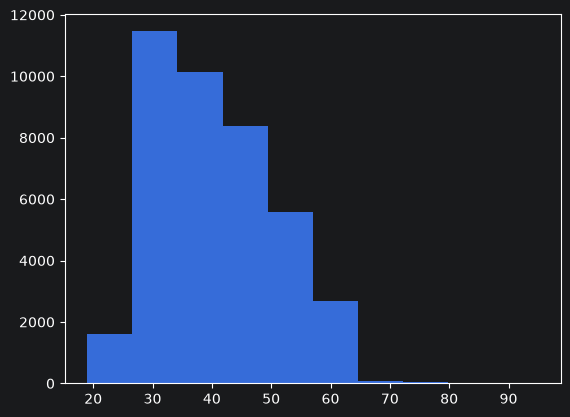

In [115]:
plt.hist(df["age"])

(array([3.5363e+04, 4.3170e+03, 2.4600e+02, 4.4000e+01, 1.8000e+01,
        5.0000e+00, 5.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00]),
 array([ -8019. ,   2995.6,  14010.2,  25024.8,  36039.4,  47054. ,
         58068.6,  69083.2,  80097.8,  91112.4, 102127. ]),
 <BarContainer object of 10 artists>)

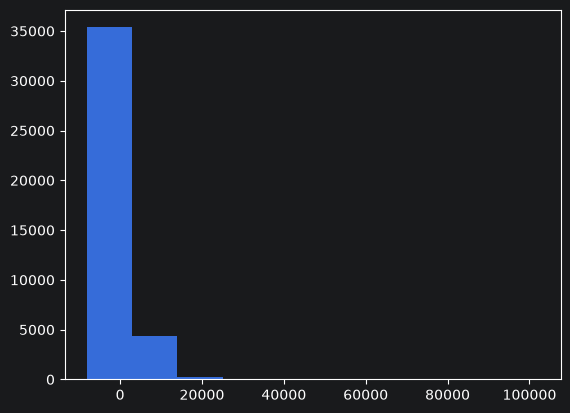

In [116]:
plt.hist(df["balance"])

(array([2.000e+00, 0.000e+00, 3.000e+00, 3.600e+01, 6.899e+03]),
 array([-8019. , -6415.2, -4811.4, -3207.6, -1603.8,     0. ]),
 <BarContainer object of 5 artists>)

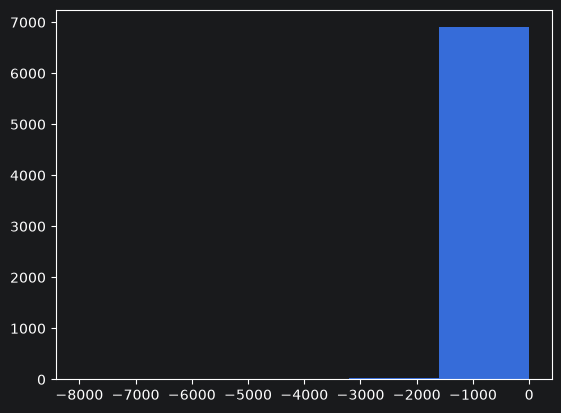

In [117]:
#another Histogram of just negative balances.
plt.hist(df["balance"], bins= 5, range=(-8019, 0))

In [118]:
#Couting outliers
(df['balance'] < -1000).sum()

np.int64(143)

In [119]:
(df['balance'] < -2000).sum()

np.int64(14)

(array([2., 0., 0., 3., 9.]),
 array([-8019. , -6815.2, -5611.4, -4407.6, -3203.8, -2000. ]),
 <BarContainer object of 5 artists>)

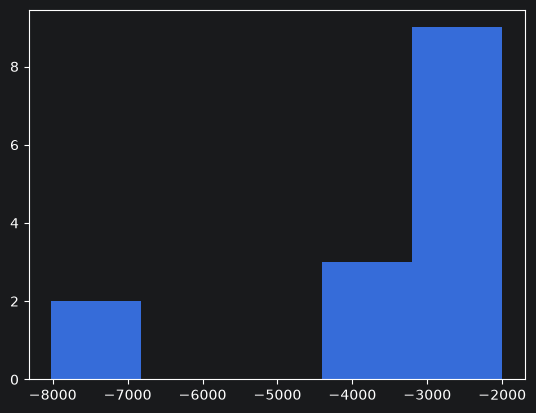

In [120]:
plt.hist(df["balance"], bins= 5, range=(-8019, -2000))

In [121]:
df[df["balance"] < -2000]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
1896,57,self-employed,married,tertiary,yes,-3313,yes,yes,unknown,9,may,153,1,no
7413,43,management,married,tertiary,yes,-3372,yes,no,unknown,29,may,386,2,no
7756,49,management,divorced,tertiary,no,-2049,yes,no,unknown,30,may,169,3,no
12909,26,blue-collar,single,secondary,yes,-8019,no,yes,cellular,7,jul,299,3,no
13687,38,blue-collar,divorced,secondary,no,-2093,yes,yes,unknown,9,jul,120,3,no
14434,51,management,divorced,tertiary,no,-2282,yes,yes,cellular,14,jul,301,6,no
15682,49,management,married,tertiary,yes,-6847,no,yes,cellular,21,jul,206,1,no
17159,51,entrepreneur,married,secondary,yes,-2082,no,yes,cellular,28,jul,123,6,no
18573,40,technician,married,tertiary,yes,-2827,yes,yes,cellular,31,jul,843,1,no
25119,49,blue-collar,single,primary,yes,-2604,yes,no,cellular,18,nov,142,1,no


(array([129.,  19.,   7.,   0.,   2.]),
 array([ 20000. ,  36425.4,  52850.8,  69276.2,  85701.6, 102127. ]),
 <BarContainer object of 5 artists>)

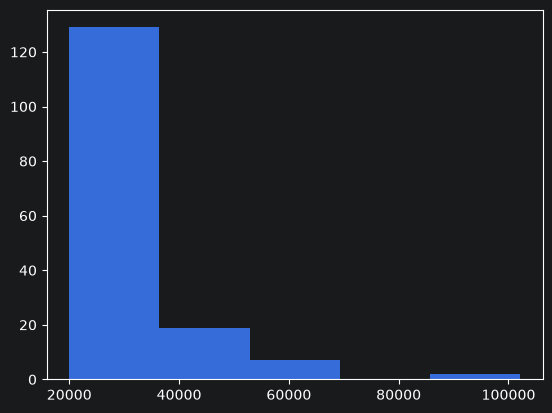

In [122]:
plt.hist(df["balance"], bins= 5, range=(20000, 102127))

In [123]:
df[df["balance"] > 80000]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
26227,59,management,married,tertiary,no,98417,no,no,telephone,20,nov,145,5,no
39989,51,management,single,tertiary,no,102127,no,no,cellular,3,jun,90,1,no


(array([3.5137e+04, 3.8610e+03, 7.8300e+02, 1.5800e+02, 3.7000e+01,
        1.1000e+01, 1.1000e+01, 1.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([   0. ,  491.8,  983.6, 1475.4, 1967.2, 2459. , 2950.8, 3442.6,
        3934.4, 4426.2, 4918. ]),
 <BarContainer object of 10 artists>)

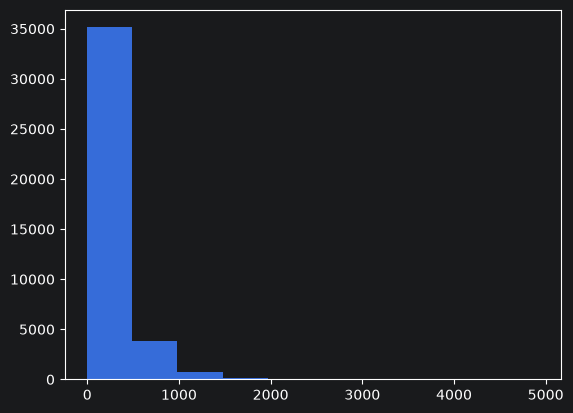

In [124]:
plt.hist(df["duration"])

(array([119.,  47.,  16.,   8.,   6.,   5.,   1.,   0.,   0.,   1.]),
 array([1500., 1850., 2200., 2550., 2900., 3250., 3600., 3950., 4300.,
        4650., 5000.]),
 <BarContainer object of 10 artists>)

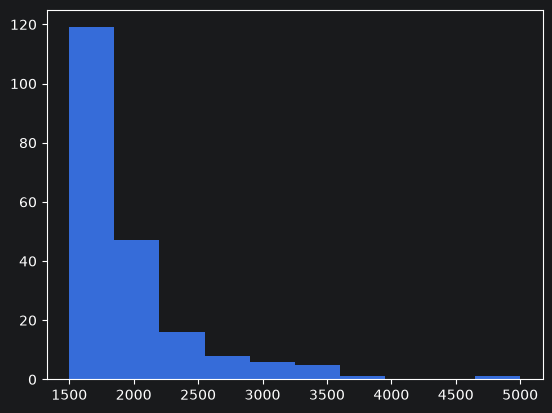

In [125]:
plt.hist(df["duration"], range=(1500,5000))

In [126]:
df[df["duration"] > 4000]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
24148,59,technician,married,tertiary,no,6573,yes,no,telephone,10,nov,4918,1,no


In [127]:
df["campaign"].value_counts()

campaign
1     14718
2     11153
3      4970
4      3297
5      1642
6      1228
7       699
8       526
9       318
10      262
11      197
12      154
13      131
14       93
15       83
16       78
17       69
18       51
19       44
20       43
21       35
22       23
25       22
23       22
24       20
28       16
29       16
26       13
31       12
27       10
32        9
30        8
33        6
34        5
35        4
36        4
43        3
38        3
41        2
50        2
37        2
51        1
63        1
55        1
46        1
58        1
39        1
44        1
Name: count, dtype: int64

(array([143.,  61.,  45.,  21.,   6.,   4.,   3.,   1.,   2.,   1.]),
 array([20. , 24.3, 28.6, 32.9, 37.2, 41.5, 45.8, 50.1, 54.4, 58.7, 63. ]),
 <BarContainer object of 10 artists>)

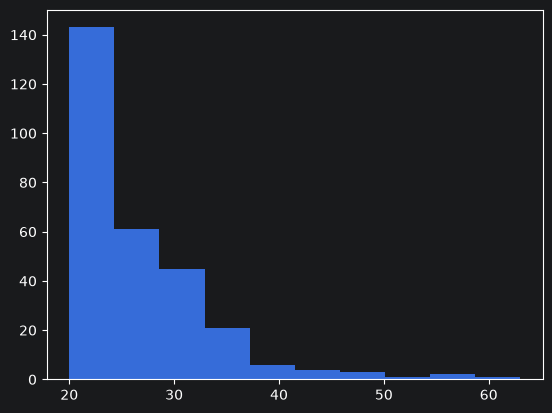

In [128]:
plt.hist(df["campaign"], bins=10, range=(20,63))

We do have some outliers. base on closer examination they do not appear to be errors. Since this analysis will use tree based machine learning models these outliers should not influence the data significantly, but they're always good to keep in mind down the road if anythign looks odd.

## Examining Categorical Data
Value Counts on the answers in each category. Checking the balance, or in this case imbalance, of the outcome variable.

In [129]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        40000 non-null  int64
 1   job        40000 non-null  str  
 2   marital    40000 non-null  str  
 3   education  40000 non-null  str  
 4   default    40000 non-null  str  
 5   balance    40000 non-null  int64
 6   housing    40000 non-null  str  
 7   loan       40000 non-null  str  
 8   contact    40000 non-null  str  
 9   day        40000 non-null  int64
 10  month      40000 non-null  str  
 11  duration   40000 non-null  int64
 12  campaign   40000 non-null  int64
 13  y          40000 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.3 MB


In [130]:
df["job"].value_counts()

job
blue-collar      9383
management       8166
technician       6852
admin            4483
services         3910
retired          1437
self-employed    1414
entrepreneur     1405
unemployed       1104
housemaid        1087
student           524
unknown           235
Name: count, dtype: int64

In [131]:
df["marital"].value_counts()

marital
married     24386
single      10889
divorced     4725
Name: count, dtype: int64

In [132]:
df["education"].value_counts()

education
secondary    20993
tertiary     11206
primary       6270
unknown       1531
Name: count, dtype: int64

In [133]:
#credit in default
df["default"].value_counts()

default
no     39191
yes      809
Name: count, dtype: int64

In [134]:
#home loan
df["housing"].value_counts()

housing
yes    24031
no     15969
Name: count, dtype: int64

In [135]:
#personal loan
df["loan"].value_counts()

loan
no     33070
yes     6930
Name: count, dtype: int64

In [136]:
df["contact"].value_counts()

contact
cellular     24914
unknown      12765
telephone     2321
Name: count, dtype: int64

In [137]:
df["month"].value_counts()

month
may    13532
jul     6380
aug     5215
jun     4734
nov     3598
apr     2718
feb     2296
jan     1176
mar      258
oct       80
dec       13
Name: count, dtype: int64

In [138]:
proportion = df["y"].value_counts(normalize=True)
count = df["y"].value_counts()
pd.concat([count, proportion], axis=1, keys=['Count', 'Proportion'])

,Count,Proportion
y,,
no,37104,0.9276
yes,2896,0.0724


This is our target variable and this is a very imbalanced dataset with less than 10% of customers having subscribed to a term deposit.

## Examining the relationships within the data

Text(0, 0.5, 'Term Deposit')

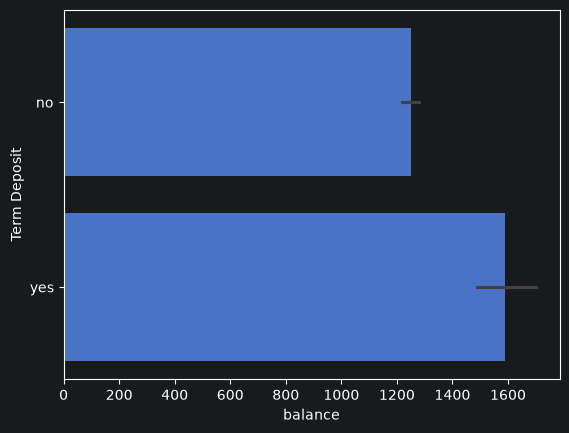

In [139]:
sns.barplot(df, x="balance", y="y")
plt.ylabel("Term Deposit")


In [140]:
df.groupby("y")["balance"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,37104.0,1249.752533,2900.722436,-8019.0,50.0,395.0,1286.0,102127.0
yes,2896.0,1588.495856,2924.894429,-3058.0,141.0,620.0,1820.5,45248.0


In [141]:
df.groupby("y")["job"].value_counts()

y    job          
no   blue-collar      8848
     management       7490
     technician       6355
     admin            4132
     services         3672
     entrepreneur     1317
     self-employed    1302
     retired          1286
     housemaid        1034
     unemployed       1008
     student           442
     unknown           218
yes  management        676
     blue-collar       535
     technician        497
     admin             351
     services          238
     retired           151
     self-employed     112
     unemployed         96
     entrepreneur       88
     student            82
     housemaid          53
     unknown            17
Name: count, dtype: int64

In [142]:
pd.crosstab(df["y"], df["job"], normalize="index")

job,admin,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
y,,,,,,,,,,,,
no,0.111363,0.238465,0.035495,0.027868,0.201865,0.034659,0.035091,0.098965,0.011912,0.171275,0.027167,0.005875
yes,0.121202,0.184738,0.030387,0.018301,0.233425,0.052141,0.038674,0.082182,0.028315,0.171616,0.033149,0.005870


This table shows what proportion of each job is represented within each term deposit possibility. We can see that management followed by blue-collar are the occupations that hold the most term deposits and unknown holds the fewest. it is worth noting, however that the two highest reported careers in this data set were blue-collar, followed by management, and unknown was the least reported job. Management having fewer responses than blue-collar and more term deposits is something to consider though.

In [143]:
pd.crosstab(df["y"], df["marital"], normalize="index")

marital,divorced,married,single
y,,,
no,0.116807,0.617400,0.265793
yes,0.135014,0.510359,0.354627


Here we can see that divorced and single people make up higher proportions of the term deposit than they do of the no term deposit group. Married folks make up the highest proportion of both, but they are also the highest proportion of the data set. It is possible that single and divorced people are more likely to store their wealth in a term deposit rather than physical assets. Let's take a look at home loans to see how that holds up.

In [144]:
pd.crosstab(df["y"], df["housing"], normalize="index")

housing,no,yes
y,,
no,0.391791,0.608209
yes,0.494475,0.505525


In [145]:
pd.crosstab(df["marital"], df["housing"], normalize="index")

housing,no,yes
marital,,
divorced,0.405503,0.594497
married,0.398958,0.601042
single,0.397098,0.602902


There is not a notable difference between married clients and single or divorced clients when it comes to owning a home, so that doesn't explain why single and divorced people had slightly hight proportions of the term deposit. Interestingly those that own a home do make up a smaller relative proportion of the people that have term deposits than of the people that do not have term deposits. Owning a home may be an important factor down the line in are model.


In [146]:
pd.crosstab(df["y"], df["education"], normalize="index")

education,primary,secondary,tertiary,unknown
y,,,,
no,0.159471,0.527571,0.274283,0.038675
yes,0.121892,0.489641,0.355318,0.033149


Here Tertiary education is the only one making up a higher proportion of the term deposit group than it did of the no term deposit group. We don't have the data here to examine this, but thinking about what we've seen so far there is likely an element of higher income/lower expenses contributing to this. Management, single individuals, more education, these are all groups that would traditional have more expendable income. the average account balance was also high for those with a term deposit.

One piece of data that is not here but maybe be helpful in the future is number of dependents, particularly children. it may be that those with more dependents have less expendable income to put into a term deposit. On the other hand, people may be motivated to open a term deposit account on behalf of a dependent and that may be a good strategy (particularly if the business wanted to target married couples).

Text(0, 0.5, 'Term Deposit')

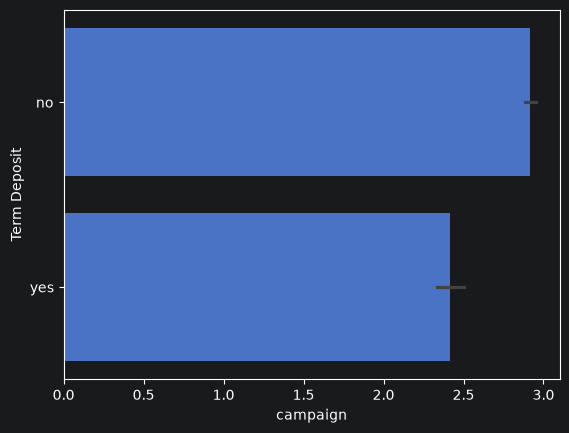

In [147]:
sns.barplot(df, x="campaign", y="y")
plt.ylabel("Term Deposit")


Text(0, 0.5, 'Term Deposit')

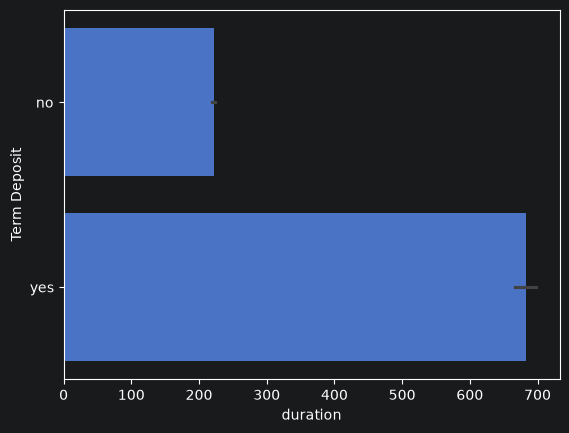

In [148]:
sns.barplot(df, x="duration", y="y")
plt.ylabel("Term Deposit")

These two bar plots suggest that more calls may not entice people to open an account, but longer calls may. It is also possible that people who are uninterested hang up immediately and therefore bring the average down.

In [149]:
pd.crosstab(df["y"], df["default"], normalize="index")

default,no,yes
y,,
no,0.979517,0.020483
yes,0.983080,0.016920


# Data Transformation
Transforming categorical data into numeric. Deciding how to handle the dates

In [150]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        40000 non-null  int64
 1   job        40000 non-null  str  
 2   marital    40000 non-null  str  
 3   education  40000 non-null  str  
 4   default    40000 non-null  str  
 5   balance    40000 non-null  int64
 6   housing    40000 non-null  str  
 7   loan       40000 non-null  str  
 8   contact    40000 non-null  str  
 9   day        40000 non-null  int64
 10  month      40000 non-null  str  
 11  duration   40000 non-null  int64
 12  campaign   40000 non-null  int64
 13  y          40000 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.3 MB


## XGBoost mode with different hyperperameters and Duration removed
I also switched from kfold to a stratified kfold which ensures that each fold contains the same percentage of target classes which can help with imbalanced data. I also changed the evaluation metric to be area under the precision recal curve, and to include the binary/logistic objective.

In [178]:
X = df.drop(columns=["y"])
y = df["y"].map({"no": 0, "yes": 1})

In [179]:
categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month']

for col in categorical_cols:
    X[col] = X[col].astype('category')

In [180]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [181]:
weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(scale_pos_weight=weight, enable_categorical=True,
                        tree_method="hist", objective="binary:logistic", random_state=42, eval_metric="aucpr")

In [182]:
cv_params = {
    'n_estimators': [300],
    'max_depth':[7,8],
    'min_child_weight':[7,8],
    'learning_rate': [0.03, 0.05],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.7, 0.8]
}

xgb_cv = GridSearchCV(xgb, cv_params, scoring='balanced_accuracy', cv=5, refit=True)

model = xgb_cv.fit(X_train, y_train)
xgb_cv.best_score_

np.float64(0.8771156159953403)

In [183]:
xgb_cv.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.03,
 'max_depth': 7,
 'min_child_weight': 8,
 'n_estimators': 300,
 'subsample': 0.8}

In [184]:
xgb_train = xgb_cv.predict(X_train)
print("Accuracy:", "%.3f" % accuracy_score(y_train, xgb_train))
print("Precision:", "%.3f" % precision_score(y_train, xgb_train))
print("Recall:", "%.3f" % recall_score(y_train, xgb_train))
print("F1 Score:", "%.3f" % f1_score(y_train, xgb_train))
print("Balanced Accuracy Score:", "%.3f" % balanced_accuracy_score(y_train, xgb_train))

Accuracy: 0.917
Precision: 0.465
Recall: 0.989
F1 Score: 0.632
Balanced Accuracy Score: 0.950


In [185]:
xgb_pred = xgb_cv.predict(X_test)
print("Accuracy:", "%.3f" % accuracy_score(y_test, xgb_pred))
print("Precision:", "%.3f" % precision_score(y_test, xgb_pred))
print("Recall:", "%.3f" % recall_score(y_test, xgb_pred))
print("F1 Score:", "%.3f" % f1_score(y_test, xgb_pred))
print("Balanced Accuracy Score:", "%.3f" % balanced_accuracy_score(y_test, xgb_pred))

Accuracy: 0.894
Precision: 0.395
Recall: 0.860
F1 Score: 0.541
Balanced Accuracy Score: 0.878


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

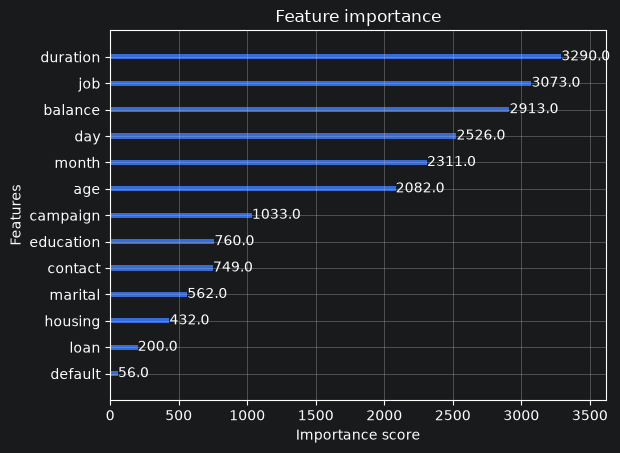

In [186]:
plot_importance(xgb_cv.best_estimator_)

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=skf, scoring= 'balanced_accuracy')

In [ ]:
print(f"Cross-Validation Balanced Accuracy Scores: {scores}")
print(f"Mean Balanced Accuracy: {scores.mean():.4f}")

In [ ]:
y_probs = xgb_cv.best_estimator_.predict_proba(X_test)[:, 1]

best_threshold = 0.5
best_bal_acc = 0

for threshold in np.arange(0.1, 0.8, 0.01):
    preds = (y_probs >= threshold).astype(int)
    score = balanced_accuracy_score(y_test, preds)
    if score > best_bal_acc:
        best_bal_acc = score
        best_threshold = threshold

print(f"🏆 Best Threshold: {best_threshold:.2f}")
print(f"🚀 Optimized Test Balanced Accuracy: {best_bal_acc:.4f}\n")

best_preds = (y_probs >= best_threshold).astype(int)
print(classification_report(y_test, best_preds))

In [ ]:
cm = confusion_matrix(y_test, best_preds)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["no term deposit", "term deposit"]).plot()